# Ridge and Lasso Regression

Linear regression with a penalty on the weights, to fight overfitting. The bias is never penalized (data is centered first). Objectives follow scikit-learn's conventions so coefficients are directly comparable.

| | Penalty | Objective | Solver | Effect |
|---|---|---|---|---|
| **Ridge** | L2 | `‖y − Xw‖² + α‖w‖²` | closed form `(XᵀX + αI)⁻¹Xᵀy` | shrinks all weights smoothly |
| **Lasso** | L1 | `1/(2n)‖y − Xw‖² + α‖w‖₁` | coordinate descent + soft-thresholding | sets some weights exactly to 0 (feature selection) |

`alpha=0` for Ridge is ordinary least squares (`01_linear_regression`). Larger `alpha` means stronger shrinkage.

Standardize features first if they have different scales — the penalty treats all weights equally.

## Usage

```python
# (the class is defined in the Implementation section below)

ridge = RidgeRegression(alpha=10.0).fit(X_train, y_train)
lasso = LassoRegression(alpha=1.0).fit(X_train, y_train)
print(lasso.weights)          # irrelevant features come out as exactly 0
preds = ridge.predict(X_test)
```

This notebook is self-contained: the explanation, the implementation, the visuals, the scikit-learn check and the tests are all here.

## Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False})

## Implementation

The whole algorithm, as a plain Python class (numpy only).

In [2]:
import numpy as np


def _center(X, y):
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float)
    return X, y, X.mean(axis=0), y.mean()


class RidgeRegression:
    """Least squares + L2 penalty:  ||y - Xw||^2 + alpha * ||w||^2   (closed form).
    The bias is not penalized: data is centered, then the bias is recovered from the means."""

    def __init__(self, alpha=1.0):
        self.alpha = alpha
        self.weights = None
        self.bias = 0.0

    def fit(self, X, y):
        X, y, x_mean, y_mean = _center(X, y)
        Xc, yc = X - x_mean, y - y_mean
        A = Xc.T @ Xc + self.alpha * np.eye(X.shape[1])
        self.weights = np.linalg.solve(A, Xc.T @ yc)
        self.bias = y_mean - x_mean @ self.weights
        return self

    def predict(self, X):
        return np.asarray(X, dtype=float) @ self.weights + self.bias


class LassoRegression:
    """Least squares + L1 penalty:  1/(2n) * ||y - Xw||^2 + alpha * ||w||_1
    solved by cyclic coordinate descent. The L1 penalty drives some weights exactly to 0."""

    def __init__(self, alpha=1.0, max_iter=1000, tol=1e-8):
        self.alpha = alpha
        self.max_iter = max_iter
        self.tol = tol
        self.weights = None
        self.bias = 0.0

    def fit(self, X, y):
        X, y, x_mean, y_mean = _center(X, y)
        Xc, yc = X - x_mean, y - y_mean
        n, d = Xc.shape
        col_sq = (Xc**2).sum(axis=0)

        w = np.zeros(d)
        residual = yc.copy()  # yc - Xc @ w, kept up to date incrementally
        for _ in range(self.max_iter):
            max_change = 0.0
            for j in range(d):
                if col_sq[j] == 0:
                    continue
                old = w[j]
                rho = Xc[:, j] @ residual + col_sq[j] * old  # correlation with residual excluding feature j
                # soft-thresholding: shrink toward 0 by n * alpha, clip at 0
                w[j] = np.sign(rho) * max(abs(rho) - n * self.alpha, 0.0) / col_sq[j]
                residual -= Xc[:, j] * (w[j] - old)
                max_change = max(max_change, abs(w[j] - old))
            if max_change < self.tol:
                break

        self.weights = w
        self.bias = y_mean - x_mean @ w
        return self

    def predict(self, X):
        return np.asarray(X, dtype=float) @ self.weights + self.bias

## See it work

### 1. Coefficient paths: how the penalty shrinks the weights

Data with 10 features of which only 4 matter. As the penalty `alpha` grows, **ridge** shrinks every weight smoothly toward zero but never exactly to zero. **Lasso** drives the unimportant weights to *exactly* zero one by one, which is automatic feature selection.

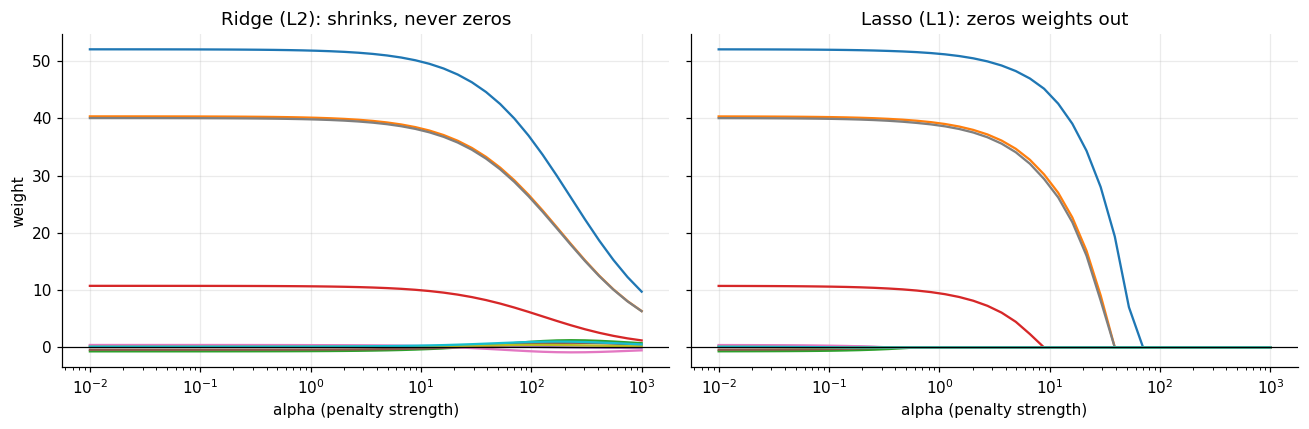

In [3]:
from sklearn.datasets import make_regression

X, y = make_regression(n_samples=200, n_features=10, n_informative=4, noise=5.0, random_state=0)
alphas = np.logspace(-2, 3, 40)
ridge_path = np.array([RidgeRegression(alpha=a).fit(X, y).weights for a in alphas])
lasso_path = np.array([LassoRegression(alpha=a).fit(X, y).weights for a in alphas])

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, path, title in [(axes[0], ridge_path, "Ridge (L2): shrinks, never zeros"), (axes[1], lasso_path, "Lasso (L1): zeros weights out")]:
    ax.semilogx(alphas, path); ax.set(title=title, xlabel="alpha (penalty strength)"); ax.axhline(0, color="k", lw=0.8)
axes[0].set_ylabel("weight")
plt.tight_layout(); plt.show()

### 2. Why L1 gives zeros and L2 does not

Minimise the loss while keeping the weights inside a budget. The budget region for L2 is a **disc** (smooth, so the loss contours touch it at a generic point where both weights are nonzero). For L1 it is a **diamond** with corners on the axes, and the contours tend to touch it at a corner, where one weight is exactly zero.

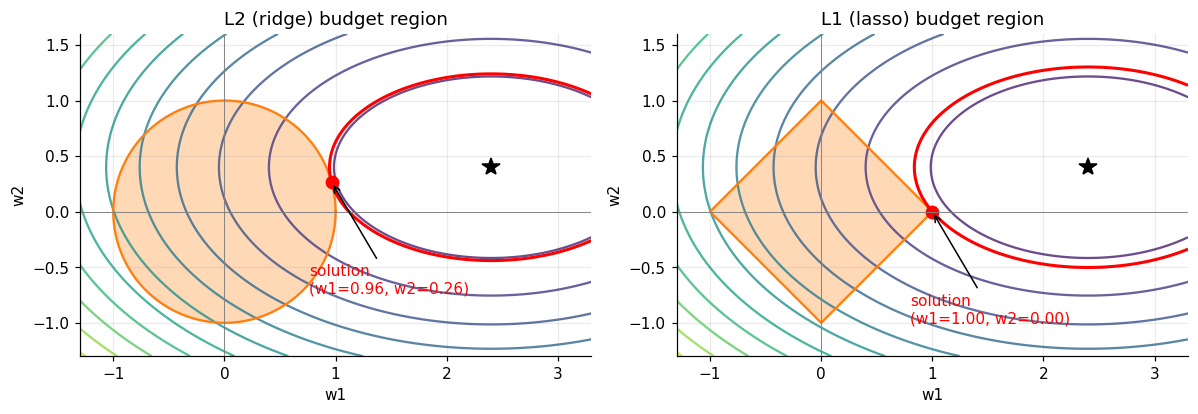

In [4]:
t = np.linspace(0, 2 * np.pi, 400)
loss_centre = np.array([2.4, 0.4])
gx, gy = np.meshgrid(np.linspace(-1.3, 3.3, 250), np.linspace(-1.3, 1.6, 250))
loss = (gx - loss_centre[0]) ** 2 + 3 * (gy - loss_centre[1]) ** 2

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for ax, kind in zip(axes, ["L2 (ridge)", "L1 (lasso)"]):
    ax.contour(gx, gy, loss, levels=12, cmap="viridis", alpha=0.8)
    if kind.startswith("L2"):
        ax.fill(np.cos(t), np.sin(t), alpha=0.3, color="C1"); ax.plot(np.cos(t), np.sin(t), "C1")
    else:
        d = np.array([[1, 0], [0, 1], [-1, 0], [0, -1], [1, 0]]); ax.fill(d[:, 0], d[:, 1], alpha=0.3, color="C1"); ax.plot(d[:, 0], d[:, 1], "C1")
    if kind.startswith("L2"):
        bx, by = np.cos(t), np.sin(t)
    else:
        bx, by = np.concatenate([np.linspace(1, 0, 100), np.linspace(0, -1, 100), np.linspace(-1, 0, 100), np.linspace(0, 1, 100)]), np.concatenate([np.linspace(0, 1, 100), np.linspace(1, 0, 100), np.linspace(0, -1, 100), np.linspace(-1, 0, 100)])
    bl = (bx - loss_centre[0]) ** 2 + 3 * (by - loss_centre[1]) ** 2
    k = bl.argmin()
    ax.contour(gx, gy, loss, levels=[bl[k]], colors="r", linewidths=2); ax.plot(bx[k], by[k], "ro", ms=8)   # the contour that just touches the region
    ax.annotate(f"solution\n(w1={bx[k]:.2f}, w2={by[k]:.2f})", (bx[k], by[k]), (bx[k] - 0.2, by[k] - 1.0), arrowprops=dict(arrowstyle="->"), color="r")
    ax.plot(*loss_centre, "k*", ms=12); ax.axhline(0, color="gray", lw=0.6); ax.axvline(0, color="gray", lw=0.6)
    ax.set(title=f"{kind} budget region", xlabel="w1", ylabel="w2"); ax.set_aspect("equal")
plt.tight_layout(); plt.show()

### 3. Shrinkage helps when features are noisy and plentiful

Few samples, many features: ordinary least squares overfits (huge test error), ridge/lasso with the right penalty generalise much better.

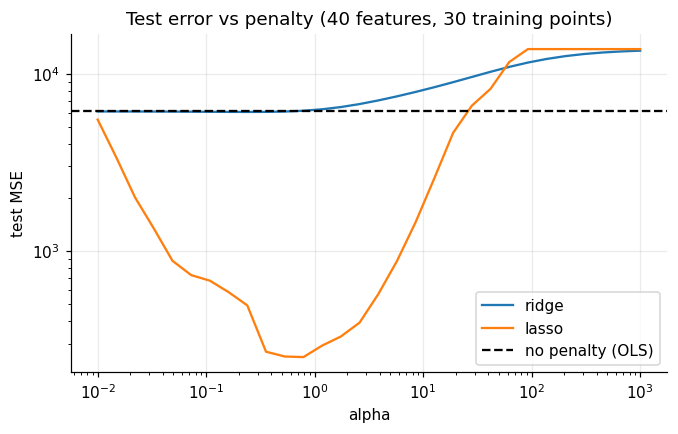

In [5]:
from sklearn.model_selection import train_test_split

Xw, yw = make_regression(n_samples=60, n_features=40, n_informative=5, noise=15.0, random_state=1)
Xtr, Xte, ytr, yte = train_test_split(Xw, yw, test_size=0.5, random_state=1)
alphas = np.logspace(-2, 3, 30)
mse = lambda m: np.mean((m.predict(Xte) - yte) ** 2)
ridge_err = [mse(RidgeRegression(alpha=a).fit(Xtr, ytr)) for a in alphas]
lasso_err = [mse(LassoRegression(alpha=a).fit(Xtr, ytr)) for a in alphas]
plt.figure(figsize=(7, 4))
plt.semilogx(alphas, ridge_err, label="ridge"); plt.semilogx(alphas, lasso_err, label="lasso")
plt.axhline(mse(RidgeRegression(alpha=1e-9).fit(Xtr, ytr)), color="k", ls="--", label="no penalty (OLS)")
plt.xlabel("alpha"); plt.ylabel("test MSE"); plt.yscale("log"); plt.title("Test error vs penalty (40 features, 30 training points)"); plt.legend(); plt.show()

## Check against a reference implementation

Same data, same settings as scikit-learn (or scipy / the real library). The assertions fail if the two disagree.

In [6]:
import numpy as np
from sklearn.datasets import make_regression
from sklearn.linear_model import Lasso, Ridge

# 10 features, only 4 actually matter
X, y = make_regression(n_samples=200, n_features=10, n_informative=4, noise=5.0, random_state=0)

ridge_ours = RidgeRegression(alpha=10.0).fit(X, y)
ridge_theirs = Ridge(alpha=10.0).fit(X, y)
lasso_ours = LassoRegression(alpha=1.0).fit(X, y)
lasso_theirs = Lasso(alpha=1.0, tol=1e-10, max_iter=100000).fit(X, y)

np.set_printoptions(precision=2, suppress=True, linewidth=120)
print("ridge  ours  :", ridge_ours.weights)
print("ridge  sklearn:", ridge_theirs.coef_)
print("lasso  ours  :", lasso_ours.weights)
print("lasso  sklearn:", lasso_theirs.coef_)
print("lasso zeroed %d of 10 features" % (lasso_ours.weights == 0).sum())

assert np.allclose(ridge_ours.weights, ridge_theirs.coef_, atol=1e-6)
assert np.allclose(ridge_ours.bias, ridge_theirs.intercept_, atol=1e-6)
assert np.allclose(lasso_ours.weights, lasso_theirs.coef_, atol=1e-4)
assert np.allclose(lasso_ours.bias, lasso_theirs.intercept_, atol=1e-4)

ridge  ours  : [49.94 38.27 -0.34  9.99  0.26 -0.19  0.21 37.96  0.21  0.32]
ridge  sklearn: [49.94 38.27 -0.34  9.99  0.26 -0.19  0.21 37.96  0.21  0.32]
lasso  ours  : [51.3  39.17 -0.    9.46  0.   -0.    0.   38.78  0.    0.  ]
lasso  sklearn: [51.3  39.17 -0.    9.46  0.   -0.    0.   38.78  0.    0.  ]
lasso zeroed 6 of 10 features


## Tests

Plain `assert` tests that check the invariants of the algorithm.

In [7]:
import numpy as np


def _data():
    rng = np.random.default_rng(0)
    X = rng.normal(size=(200, 6))
    true_w = np.array([4.0, -3.0, 2.0, 0.0, 0.0, 0.0])  # last three features are irrelevant
    y = X @ true_w + 5.0 + rng.normal(scale=0.5, size=200)
    return X, y, true_w


def test_ridge_alpha_zero_is_ordinary_least_squares():
    X, y, true_w = _data()
    model = RidgeRegression(alpha=0.0).fit(X, y)
    assert np.allclose(model.weights, true_w, atol=0.2)
    assert abs(model.bias - 5.0) < 0.2


def test_ridge_shrinks_weights_as_alpha_grows():
    X, y, _ = _data()
    norms = [np.linalg.norm(RidgeRegression(alpha=a).fit(X, y).weights) for a in (0, 10, 1000, 1e6)]
    assert norms == sorted(norms, reverse=True)
    assert norms[-1] < 0.01


def test_lasso_zeroes_irrelevant_features():
    X, y, true_w = _data()
    model = LassoRegression(alpha=0.1).fit(X, y)
    assert (model.weights[3:] == 0).all()  # exact zeros, not just small
    assert np.allclose(model.weights[:3], true_w[:3], atol=0.3)


def test_lasso_huge_alpha_gives_all_zero_weights():
    X, y, _ = _data()
    model = LassoRegression(alpha=1e3).fit(X, y)
    assert (model.weights == 0).all()
    assert abs(model.bias - y.mean()) < 1e-9

In [8]:
tests = [(name, fn) for name, fn in list(globals().items()) if name.startswith("test_") and callable(fn)]
for name, fn in tests:
    fn()
    print("PASS", name)
print(f"\nall {len(tests)} tests passed")

PASS test_ridge_alpha_zero_is_ordinary_least_squares
PASS test_ridge_shrinks_weights_as_alpha_grows
PASS test_lasso_zeroes_irrelevant_features
PASS test_lasso_huge_alpha_gives_all_zero_weights

all 4 tests passed


## Takeaways

- **Ridge** (L2): keeps all features, shrinks correlated ones together, closed form `solve(XᵀX + αI, Xᵀy)`. Use when many features each contribute a little.
- **Lasso** (L1): sparse solutions, i.e. feature selection; no closed form, solved by coordinate descent with the soft-threshold `sign(ρ)·max(|ρ| − α, 0)`. Use when you believe few features matter. With correlated features it picks one arbitrarily (see `03_elastic_net`).
- **Always** standardise features first (the penalty treats all weights equally) and never penalise the bias (the code centres the data to avoid it).
- **Interview line:** *"Ridge adds `α‖w‖²`, lasso adds `α‖w‖₁`. L1's diamond-shaped constraint has corners on the axes, so it produces exact zeros."*